EDA.1 Cargar, estandarizar y validar 


In [21]:

import os
import pandas as pd
import numpy as np

# --- Ubicar el CSV limpio desde notebooks/ ---
PROJECT_ROOT = os.path.abspath("..")
DATA_PATH = r"C:\Users\ASUS\Desktop\Escritorio\Programar\Projects\gdp_life_expectancy_project\data\processed\all_data_processed.csv"


df = pd.read_csv(DATA_PATH)

# (Opcional) Estandarizar nombres si vinieran distintos
rename_map = {
    "pais": "Country", "país": "Country", "country": "Country", "Country": "Country",
    "anio": "Year", "año": "Year", "ano": "Year", "year": "Year", "Year": "Year",
    "esperanza_de_vida": "LifeExpectancy", "esperanza de vida": "LifeExpectancy",
    "life_expectancy": "LifeExpectancy", "Life expectancy at birth (years)": "LifeExpectancy", "LifeExpectancy": "LifeExpectancy",
    "pbi": "GDP", "pib": "GDP", "gdp": "GDP", "GDP": "GDP"
}
df = df.rename(columns={c: rename_map.get(c, c) for c in df.columns})

# Dejar solo las 4 columnas esperadas y en orden
df = df[["Country", "Year", "LifeExpectancy", "GDP"]]

# Tipos
df["Year"] = df["Year"].astype(int)
df["LifeExpectancy"] = pd.to_numeric(df["LifeExpectancy"], errors="coerce")
df["GDP"] = pd.to_numeric(df["GDP"], errors="coerce")

# Validaciones rápidas
print("Dimensiones:", df.shape)          # esperado (96, 4)
print("Años:", df["Year"].min(), "-", df["Year"].max())  # 2000 - 2015
print("Países:", sorted(df["Country"].unique()))

print("\nNulos por columna:\n", df.isnull().sum())
print("\nDuplicados país-año:", df.duplicated(subset=["Country","Year"]).sum())

# Ordenar por país y año
df = df.sort_values(["Country","Year"]).reset_index(drop=True)
df.head()


Dimensiones: (96, 4)
Años: 2000 - 2015
Países: ['Chile', 'China', 'Germany', 'Mexico', 'United States of America', 'Zimbabwe']

Nulos por columna:
 Country           0
Year              0
LifeExpectancy    0
GDP               0
dtype: int64

Duplicados país-año: 0


,Country,Year,LifeExpectancy,GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


EDA.2 Resumen descriptivo por pais

In [22]:
# Estadísticas básicas por país
desc = df.groupby("Country")[["LifeExpectancy","GDP"]].agg(["min","max","mean"]).round(2)
desc


LifeExpectancy                        GDP  \
                                    min   max   mean           min   
Country                                                              
Chile                              77.3  80.5  78.94  6.973681e+10   
China                              71.7  76.1  74.26  1.211350e+12   
Germany                            78.0  81.0  79.66  1.949950e+12   
Mexico                             74.8  76.7  75.72  6.836480e+11   
United States of America           76.8  79.3  78.06  1.030000e+13   
Zimbabwe                           44.3  60.7  50.09  4.415703e+09   

                                                      
                                   max          mean  
Country                                               
Chile                     2.783840e+11  1.697888e+11  
China                     1.106470e+13  4.957714e+12  
Germany                   3.890610e+12  3.094776e+12  
Mexico                    1.298460e+12  9.766506e+11  
United States of America  1.810000e+13  1.407500e+13  
Zimbabwe                  1.630467e+10  9.062580e+09

EDA.3 Tendencias temporales

A) Esperanza de vida (linea por país)

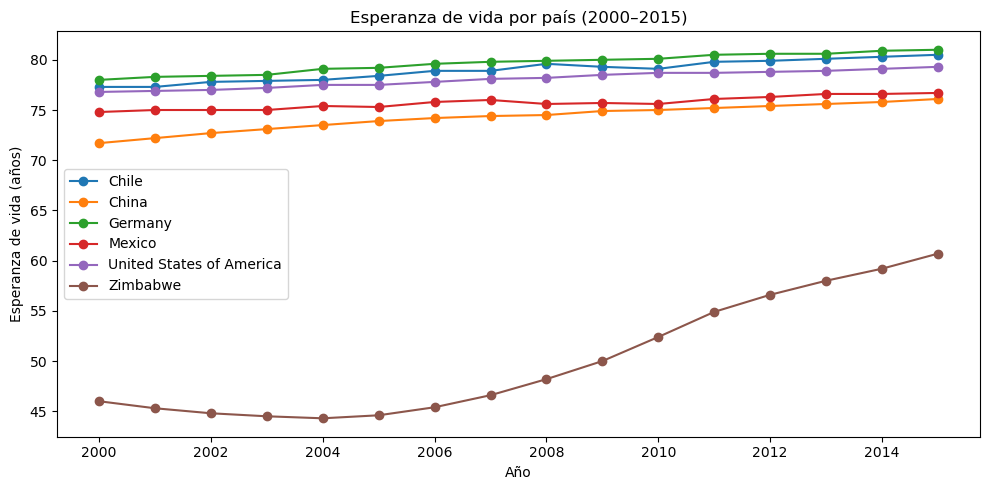

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
for country, g in df.groupby("Country"):
    plt.plot(g["Year"], g["LifeExpectancy"], marker="o", label=country)

plt.title("Esperanza de vida por país (2000–2015)")
plt.xlabel("Año")
plt.ylabel("Esperanza de vida (años)")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/life_expectancy_trends.png", dpi=300, bbox_inches="tight")
plt.show()




B) PBI (linea por país)

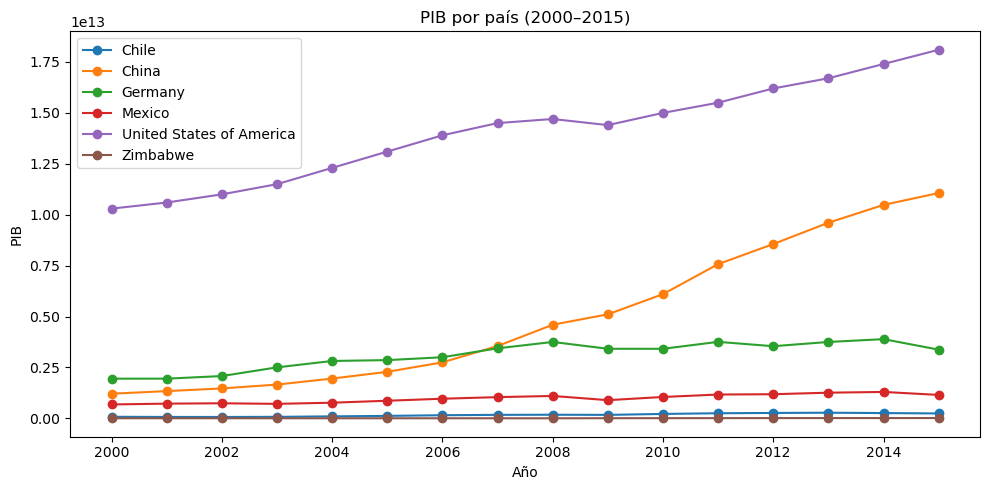

In [24]:
plt.figure(figsize=(10,5))
for country, g in df.groupby("Country"):
    plt.plot(g["Year"], g["GDP"], marker="o", label=country)

plt.title("PIB por país (2000–2015)")
plt.xlabel("Año")
plt.ylabel("PIB")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/GDP_trends.png", dpi=300, bbox_inches="tight")
plt.show()



B.Bis) PBI (linea por país, escala logaritmica)

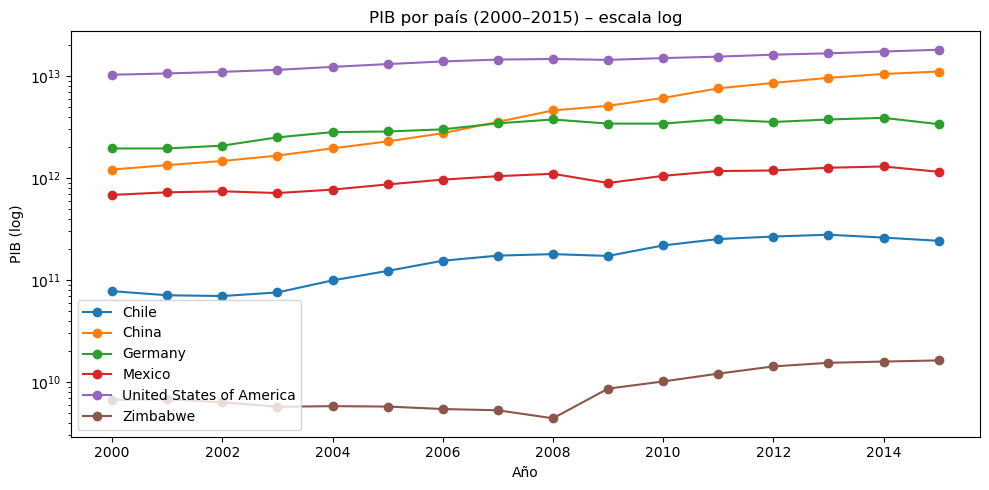

In [25]:
plt.figure(figsize=(10,5))
for country, g in df.groupby("Country"):
    plt.plot(g["Year"], g["GDP"], marker="o", label=country)

plt.yscale("log")
plt.title("PIB por país (2000–2015) – escala log")
plt.xlabel("Año")
plt.ylabel("PIB (log)")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/GDP_log_trends.png", dpi=300, bbox_inches="tight")
plt.show()


EDA.4 Relación PIB vs Esperanza de vida (dispersión)

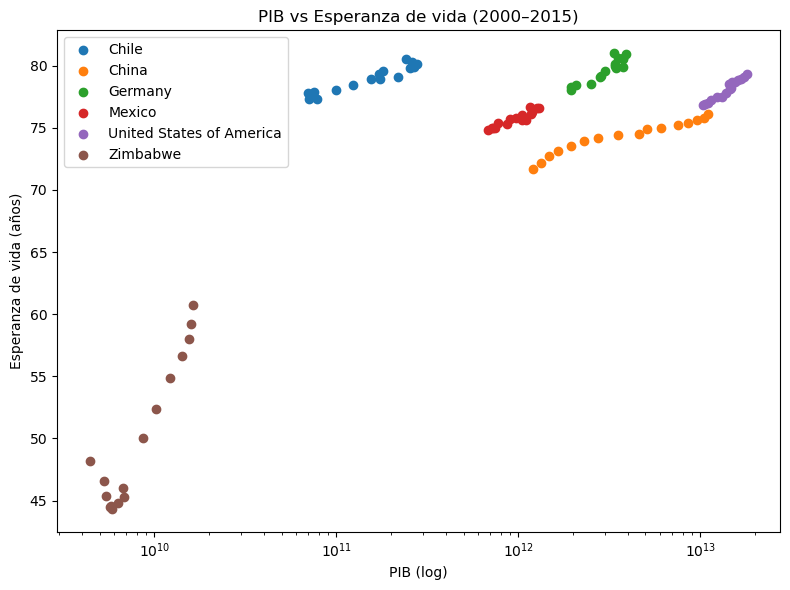

In [26]:
plt.figure(figsize=(8,6))
for country, g in df.groupby("Country"):
    plt.scatter(g["GDP"], g["LifeExpectancy"], label=country)

plt.xscale("log")  # clave para ver relación sobre varios órdenes de magnitud
plt.title("PIB vs Esperanza de vida (2000–2015)")
plt.xlabel("PIB (log)")
plt.ylabel("Esperanza de vida (años)")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/GDP_life_expectancy_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()


EDA.5 Correlación por país (Pearson y Spearman)

In [27]:
from scipy.stats import pearsonr, spearmanr

rows = []
for country, g in df.groupby("Country"):
    x = g["GDP"].values
    y = g["LifeExpectancy"].values
    pr, pp = pearsonr(x, y)     # lineal
    sr, sp = spearmanr(x, y)    # monótona (rangos)
    rows.append({
        "Country": country,
        "Pearson_r": round(pr, 3), "Pearson_p": round(pp, 4),
        "Spearman_rho": round(sr, 3), "Spearman_p": round(sp, 4)
    })

corr_df = pd.DataFrame(rows).sort_values("Pearson_r", ascending=False)
corr_df


,Country,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
4,United States of America,0.982,0.0,0.990,0.0000
5,Zimbabwe,0.966,0.0,0.753,0.0008
0,Chile,0.950,0.0,0.928,0.0000
2,Germany,0.933,0.0,0.845,0.0000
3,Mexico,0.932,0.0,0.919,0.0000
1,China,0.909,0.0,1.000,0.0000


EDA.6 Índices base 2000 (=100) para comparar crecimientos

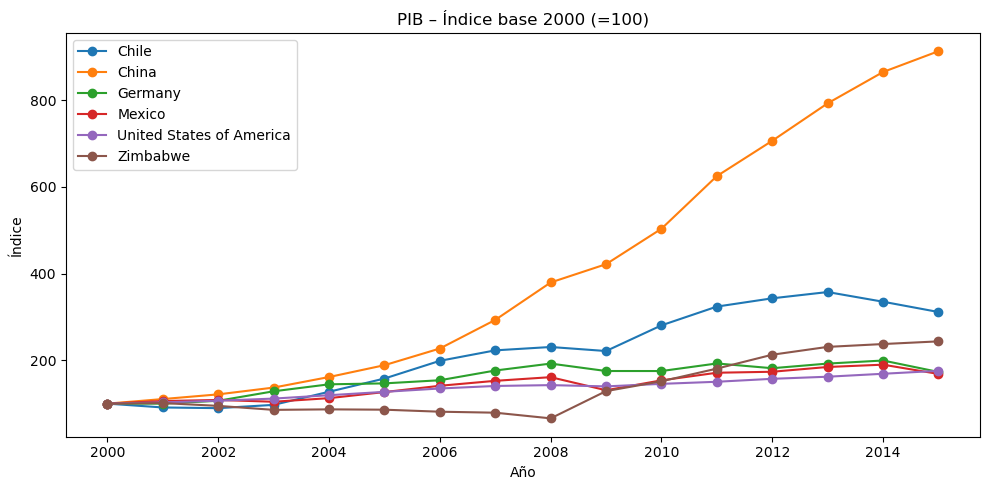

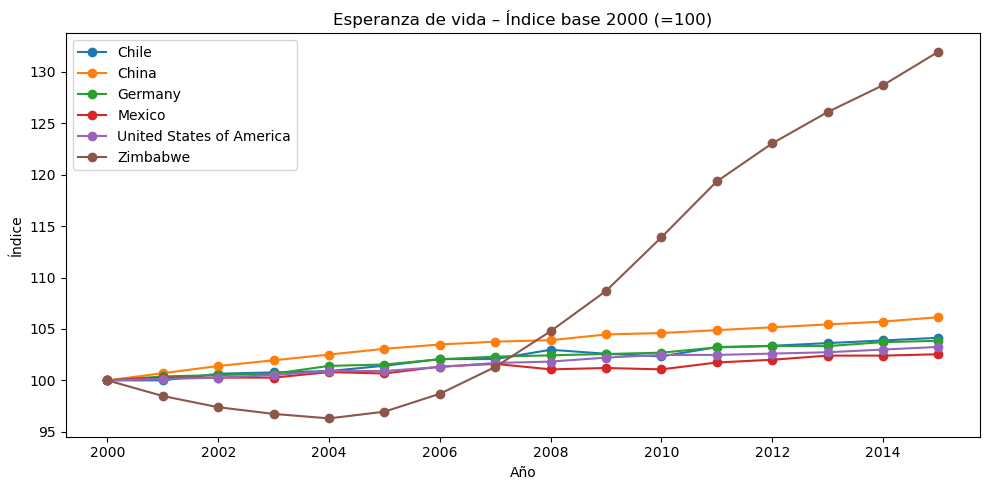

In [28]:
base = df[df["Year"] == 2000][["Country","GDP","LifeExpectancy"]].set_index("Country")
df_idx = df.join(base, on="Country", rsuffix="_base")

df_idx["GDP_idx"]  = (df_idx["GDP"] / df_idx["GDP_base"]) * 100
df_idx["Life_idx"] = (df_idx["LifeExpectancy"] / df_idx["LifeExpectancy_base"]) * 100

plt.figure(figsize=(10,5))
for country, g in df_idx.groupby("Country"):
    plt.plot(g["Year"], g["GDP_idx"], marker="o", label=country)
plt.title("PIB – Índice base 2000 (=100)")
plt.xlabel("Año"); plt.ylabel("Índice")
plt.legend(); plt.tight_layout(); plt.savefig("../reports/figures/GDP_index_2000.png", dpi=300, bbox_inches="tight"); plt.show()

plt.figure(figsize=(10,5))
for country, g in df_idx.groupby("Country"):
    plt.plot(g["Year"], g["Life_idx"], marker="o", label=country)
plt.title("Esperanza de vida – Índice base 2000 (=100)")
plt.xlabel("Año"); plt.ylabel("Índice")
plt.legend(); plt.tight_layout(); plt.savefig("../reports/figures/life_expectancy_index_2000.png", dpi=300, bbox_inches="tight"); plt.show()


EDA. Guardar dataset con columnas nuevas

In [29]:
# Guardar dataset con índices base
PROC_PATH = os.path.join(PROJECT_ROOT, "data", "processed", "gdp_life_expectancy_with_index.csv")
df_idx.to_csv(PROC_PATH, index=False)
PROC_PATH


'c:\\Users\\ASUS\\Desktop\\Escritorio\\Programar\\Projects\\gdp_life_expectancy_project\\data\\processed\\gdp_life_expectancy_with_index.csv'